# 03 · Segmentación de clientes (CRISP-DM: Modelado y Evaluación)

Se agrupan los clientes con K-Means a partir de sus variables RFM. Las variables se transforman con logaritmo y se estandarizan; el número de segmentos se elige con el método del codo y el coeficiente silhouette.

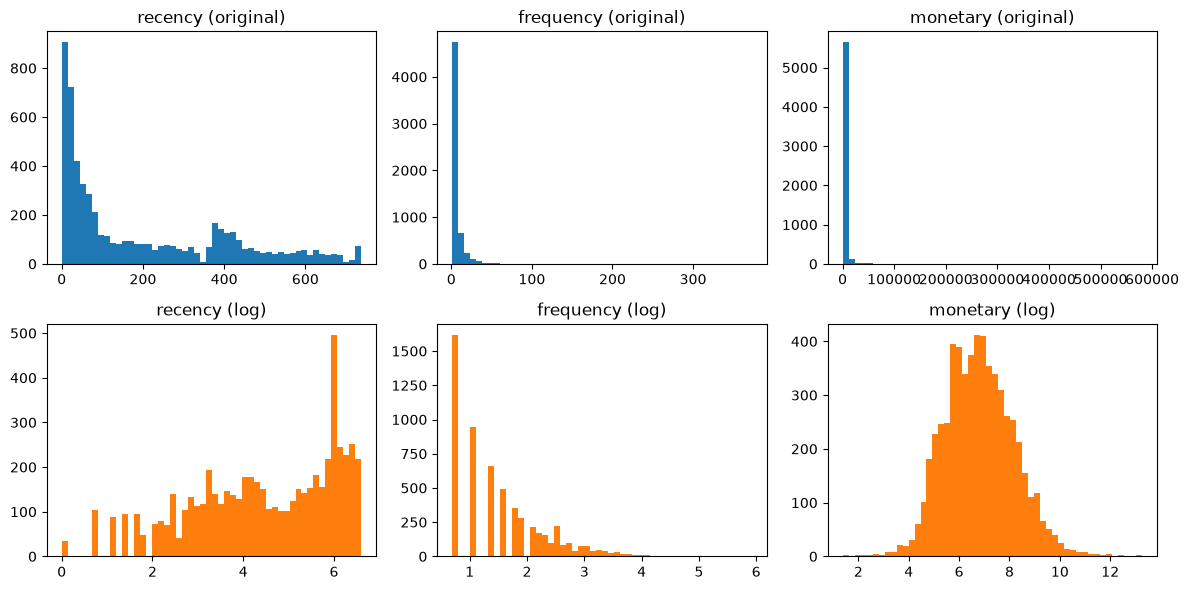

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

rfm = pd.read_csv("../data/processed/rfm.csv")
variables = ["recency", "frequency", "monetary"]

# Logaritmo para reducir el sesgo (log1p = log(1 + x), admite recency = 0)
X_log = np.log1p(rfm[variables])

# Estandarizar: cada variable con media 0 y desviación 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# Antes y después del logaritmo
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, var in enumerate(variables):
    axes[0, i].hist(rfm[var], bins=50)
    axes[0, i].set_title(f"{var} (original)")
    axes[1, i].hist(X_log[var], bins=50, color="tab:orange")
    axes[1, i].set_title(f"{var} (log)")
plt.tight_layout()
plt.savefig("../reports/figuras/distribucion_rfm_log.png", dpi=150)
plt.show()

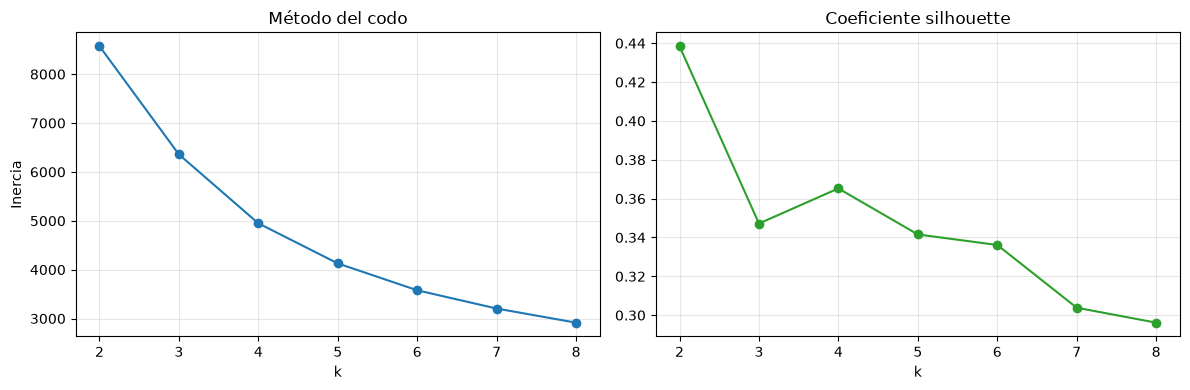

,k,inercia,silhouette
0,2,8572.745,0.438
1,3,6358.499,0.347
2,4,4948.336,0.365
3,5,4128.217,0.342
4,6,3578.145,0.336
5,7,3204.687,0.304
6,8,2915.616,0.296


In [2]:
resultados = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km.fit_predict(X_scaled)
    resultados.append({
        "k": k,
        "inercia": km.inertia_,
        "silhouette": silhouette_score(X_scaled, etiquetas),
    })
res = pd.DataFrame(resultados)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(res["k"], res["inercia"], marker="o")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia")
axes[1].plot(res["k"], res["silhouette"], marker="o", color="tab:green")
axes[1].set_title("Coeficiente silhouette")
axes[1].set_xlabel("k")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../reports/figuras/codo_silhouette.png", dpi=150)
plt.show()

res.round(3)

## Elección de k

Se elige **k = 4**: el silhouette es máximo en k = 2 (0.438), pero dos grupos no permiten acciones diferenciadas y quedan fuera del criterio de negocio (3 a 6 segmentos). Dentro de ese rango, k = 4 tiene el mejor silhouette (0.365) y coincide con el codo de la inercia. La separación entre grupos es moderada, algo habitual en datos de comportamiento de clientes.

In [3]:
k = 4
kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
rfm["segmento"] = kmeans.fit_predict(X_scaled)

# Limitar la tasa de devolución a 1 (ver notebook 02)
rfm["tasa_devolucion_aj"] = rfm["tasa_devolucion"].clip(upper=1)

perfil = rfm.groupby("segmento").agg(
    clientes=("customer_id", "count"),
    recency_mediana=("recency", "median"),
    frequency_mediana=("frequency", "median"),
    monetary_mediana=("monetary", "median"),
    ventas_total=("monetary", "sum"),
    tasa_devolucion_media=("tasa_devolucion_aj", "mean"),
)
perfil["pct_clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil["pct_ventas"] = perfil["ventas_total"] / perfil["ventas_total"].sum() * 100

perfil.round(2)

,clientes,recency_mediana,frequency_mediana,monetary_mediana,ventas_total,tasa_devolucion_media,pct_clientes,pct_ventas
segmento,,,,,,,,
0,1220,23.0,3.0,707.66,1002636.17,0.02,20.85,5.87
1,1110,15.0,13.0,5117.68,12217512.16,0.02,18.97,71.58
2,2054,398.0,1.0,291.43,697806.21,0.03,35.10,4.09
3,1468,157.0,5.0,1580.42,3150628.18,0.03,25.09,18.46


In [4]:
nombres = {
    0: "Recientes ocasionales",
    1: "Campeones",
    2: "Inactivos",
    3: "En riesgo",
}
rfm["segmento_nombre"] = rfm["segmento"].map(nombres)

perfil.index = perfil.index.map(nombres)
perfil = perfil.sort_values("pct_ventas", ascending=False)
perfil.round(1)

,clientes,recency_mediana,frequency_mediana,monetary_mediana,ventas_total,tasa_devolucion_media,pct_clientes,pct_ventas
segmento,,,,,,,,
Campeones,1110,15.0,13.0,5117.7,12217512.2,0.0,19.0,71.6
En riesgo,1468,157.0,5.0,1580.4,3150628.2,0.0,25.1,18.5
Recientes ocasionales,1220,23.0,3.0,707.7,1002636.2,0.0,20.8,5.9
Inactivos,2054,398.0,1.0,291.4,697806.2,0.0,35.1,4.1


Varianza explicada por los 2 componentes: 0.951


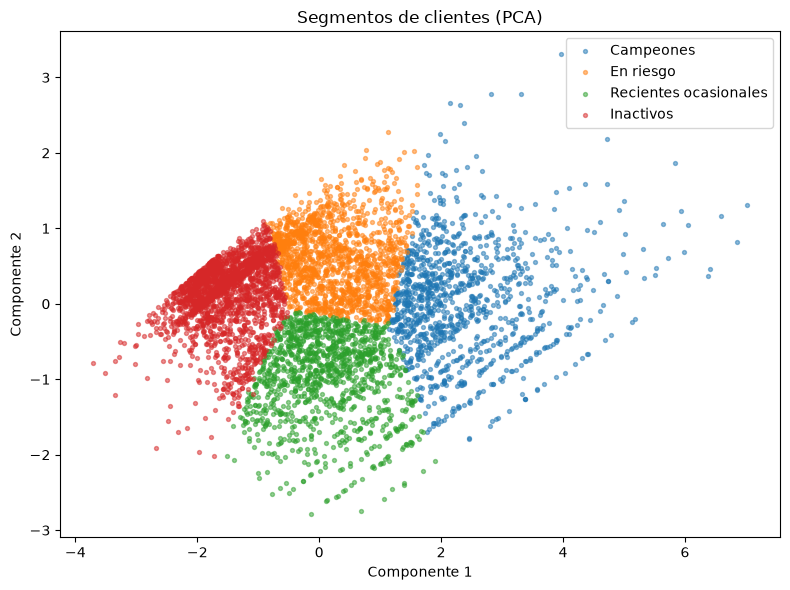

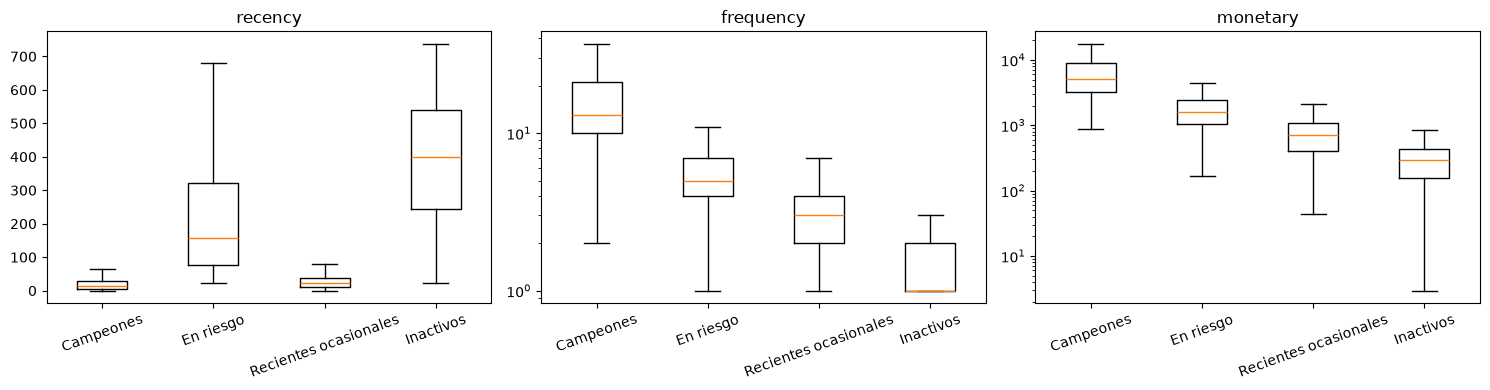

In [5]:
from sklearn.decomposition import PCA

orden = perfil.index.tolist()

# Segmentos en 2D con PCA (solo para visualizar)
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
print("Varianza explicada por los 2 componentes:", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(figsize=(8, 6))
for nombre in orden:
    idx = rfm.index[rfm["segmento_nombre"] == nombre]
    ax.scatter(coords[idx, 0], coords[idx, 1], s=8, alpha=0.5, label=nombre)
ax.set_title("Segmentos de clientes (PCA)")
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figuras/segmentos_pca.png", dpi=150)
plt.show()

# Distribución de R, F y M por segmento
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, var in zip(axes, variables):
    datos = [rfm.loc[rfm["segmento_nombre"] == n, var] for n in orden]
    ax.boxplot(datos, tick_labels=orden, showfliers=False)
    ax.set_title(var)
    ax.tick_params(axis="x", rotation=20)
    if var != "recency":
        ax.set_yscale("log")
plt.tight_layout()
plt.savefig("../reports/figuras/rfm_por_segmento.png", dpi=150)
plt.show()

In [6]:
import joblib

joblib.dump(kmeans, "../models/kmeans.pkl")
joblib.dump(scaler, "../models/scaler.pkl")
rfm.to_csv("../data/processed/rfm_segmentos.csv", index=False)
print("Guardado")

Guardado


## Segmentos y recomendaciones

| Segmento | % clientes | % ventas | Perfil (medianas) | Acción recomendada |
|---|---|---|---|---|
| Campeones | 19.0 % | 71.6 % | Última compra hace 15 días, 13 compras, £5,118 | Programa de fidelización, acceso anticipado a la campaña navideña y atención preferente. Es el grupo que más conviene proteger. |
| En riesgo | 25.1 % | 18.5 % | Hace 157 días, 5 compras, £1,580 | Campaña de reactivación antes de la temporada alta (septiembre), con ofertas basadas en sus compras anteriores. |
| Recientes ocasionales | 20.8 % | 5.9 % | Hace 23 días, 3 compras, £708 | Incentivar la siguiente compra: recomendaciones de productos y envío gratis desde cierto monto. |
| Inactivos | 35.1 % | 4.1 % | Hace 398 días, 1 compra, £291 | Acciones de bajo costo (correo masivo) y medir la respuesta antes de invertir más. |

- El 19 % de los clientes genera el 71.6 % de las ventas: la empresa depende de un grupo reducido.
- La tasa de devolución es similar en todos los segmentos (2–3 %), por lo que no los diferencia.
- Las recomendaciones son propuestas a validar; su efecto debería medirse con pruebas (por ejemplo, un grupo de control).